# R1_A2 - Animal-held-out discrimination: ANOVA d selection
Run preprocessing 00 first.

**Training objective:** maximize signed animal-balanced standardized mean difference (`anova_d`) separately for each polarity. Training AUC saturated at 1.0, so its ties selected n-plets with lower region indices. This objective replaces AUC for subset selection only; training AUC remains a diagnostic. Strategy A probability fitting and Strategy B raw-score evaluation are unchanged.

**Evaluation paths:** Strategy A pools held-out model probabilities; Strategy B pools held-out raw Omega and mean within-n-plet Fisher-z FC. Both retain performance lineplots across n-plet orders and report animal-balanced ROC-AUC and weighted average precision with responsive as the positive class. Regional subsets are selected using training animals only. Probability-score distributions/boxplots and within-animal ROC-AUC/average precision are excluded.

In [1]:
from pathlib import Path
import os
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src' / 'hoi_anesthesia').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook inside the repository.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from src.hoi_anesthesia.io import load_covariance_dict
from sklearn.metrics import average_precision_score, roc_auc_score
from src.hoi_anesthesia.validation import (
    LOAOCheckpointStore, LOAOResult, SearchSettings, build_loao_manifest,
    configure_loao_logger, load_classification_data, loao_run_id,
    run_loao_annealing, run_loao_exhaustive, save_loao_result,
    animal_balanced_weights, validate_prediction_coverage,
)

print(f'Repository root: {ROOT}')
print(f'Available compute device: {"CUDA" if torch.cuda.is_available() else "CPU"}')



c:\CAMILO\Brain_Entropy\CODES\.Brain_Entropy_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository root: c:\CAMILO\Brain_Entropy\REPO\high-order-anesthesia
Available compute device: CUDA


## Search methods
**Exhaustive search (orders 3, 4, 5):** score every regional combination in batches of batch_size and retain the largest signed animal-balanced d in each direction. With 82 regions this evaluates 88,560, 1,749,060, and 27,285,336 candidates, respectively.

**Simulated annealing (orders 6, 7, 8, 9):** search the larger spaces with 100 restarts, up to 20,000 iterations, and early stopping after 1,000 iterations without a strict improvement. Both Omega and FC use the same annealing implementation.

Both methods maximize the same fold-specific objective: polarity times (responsive mean minus nonresponsive mean), divided by the square root of the average of the two within-class weighted population variances. Weights are normalized within each class. All candidates in a batch are scored on the selected device in float64. Zero denominators and non-finite scores raise contextual errors. Responsive is positive. Each search cell displays `training_objective`, `selection_score` and diagnostic `training_auc`.

**Selection measures (`SEARCH_MEASURES`):** raw Omega `omega` (O) and mean within-n-plet Fisher-z FC `fc`; normalized Omega is excluded. Both measures use identical folds, settings and seeds. FC is computed from the preprocessed Gaussian-copula covariances, with correlations clipped to [-0.999999, 0.999999] before the Fisher-z transform. Omega is evaluated with T=None (no finite-sample entropy bias correction).

In [2]:
SETTINGS = SearchSettings(restarts=100, iterations=20000, early_stop=1000,
                          temperature=0.1, cooling=0.99, batch_size=8000, seed=2026)
SELECTION_OBJECTIVE = 'anova_d'
EXHAUSTIVE_ORDERS = (3, 4, 5)
ANNEALING_ORDERS = (6, 7, 8, 9)
DATASETS = ('MA', 'DBS')
SEARCH_MEASURES = ('omega', 'fc')
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
COVARIANCE_PATH = ROOT / 'data' / 'covariance_matrices_gc.h5'
METADATA_PATH = ROOT / 'data' / 'scan_metadata.csv'
OUTPUT = ROOT / 'results' / 'R1_A2_loao_anova'
RUN_MANIFEST = build_loao_manifest(
    COVARIANCE_PATH, METADATA_PATH, SETTINGS, DATASETS, DEVICE,
    objective=SELECTION_OBJECTIVE,
)
RUN_ID = loao_run_id(RUN_MANIFEST)
CHECKPOINT_DIR = OUTPUT / 'checkpoints' / RUN_ID
CHECKPOINTS = LOAOCheckpointStore(CHECKPOINT_DIR, RUN_MANIFEST, metadata_path=METADATA_PATH)
LOGGER = configure_loao_logger(CHECKPOINT_DIR / 'run.log')
LOGGER.info('R1 run_id=%s device=%s datasets=%s', RUN_ID, DEVICE, DATASETS)
LOGGER.info('Run manifest: %s', RUN_MANIFEST)
print(f'Run ID: {RUN_ID}')
print(f'Datasets: {DATASETS}; exhaustive orders: {EXHAUSTIVE_ORDERS}; annealing orders: {ANNEALING_ORDERS}')
display(pd.Series(RUN_MANIFEST['settings'], name='Search setting').to_frame())

2026-11-11 03:17:25,862 INFO R1 run_id=2fcca35828e99a1ec0fd device=cuda datasets=('MA', 'DBS')
2026-11-11 03:17:25,863 INFO Run manifest: {'checkpoint_schema': 1, 'algorithm_version': 1, 'inputs': {'covariance_sha256': 'b72d47513317a87f8778f0076775ca31f3bb5dd7e602f385bf3ec6bd2ff6be09', 'metadata_sha256': '61b0a957b95250169c9902c1d765e9cc546aa700132f02b8f21f8bec8a896cb2'}, 'settings': {'restarts': 100, 'iterations': 20000, 'early_stop': 1000, 'temperature': 0.1, 'cooling': 0.99, 'batch_size': 8000, 'seed': 2026}, 'datasets': ['MA', 'DBS'], 'device': 'cuda', 'orders': {'exhaustive': [3, 4, 5], 'annealing': [6, 7, 8, 9]}, 'selection_objective': 'anova_d'}


Run ID: 2fcca35828e99a1ec0fd
Datasets: ('MA', 'DBS'); exhaustive orders: (3, 4, 5); annealing orders: (6, 7, 8, 9)


,Search setting
restarts,100.00
iterations,20000.00
early_stop,1000.00
temperature,0.10
cooling,0.99
batch_size,8000.00
seed,2026.00


### Temperature and provenance
The user approved temperature **0.1** for signed d. Initially, a 0.1 decrease is accepted with probability exp(-1). This is a starting heuristic, not an empirically calibrated temperature; d is unbounded. All other SearchSettings match the reference. The manifest includes `selection_objective='anova_d'` and has its own output/checkpoint directory. Original AUC manifests omit this key and retain their run IDs. Run provenance is printed by the settings cell rather than copied from an earlier AUC run.

In [3]:
metadata = pd.read_csv(METADATA_PATH, dtype={'animal': str, 'session': str, 'run': str})
all_covariances = load_covariance_dict(COVARIANCE_PATH)
inputs = {}
input_summaries = []
for dataset in DATASETS:
    covariances, scans = load_classification_data(all_covariances, metadata, dataset)
    inputs[dataset] = (covariances, scans)
    input_summaries.append(scans.groupby(['dataset', 'animal', 'state'], as_index=False).agg(
        scans=('scan_index', 'size'), sessions=('session', 'nunique')))
    print(f'{dataset}: covariance shape={covariances.shape}; scans={len(scans)}; regions={covariances.shape[1]}')
display(pd.concat(input_summaries, ignore_index=True))

EXPECTED_SCANS = pd.concat([scans for _, scans in inputs.values()], ignore_index=True)

def validate_oof(frame, orders, measure_models, model_column='model'):
    expected_groups = [
        (dataset, order, measure, polarity, model)
        for dataset in DATASETS for order in orders
        for measure, model in measure_models for polarity in (-1, 1)
    ]
    validate_prediction_coverage(
        frame, EXPECTED_SCANS,
        ['dataset', 'order', 'selection_measure', 'polarity', model_column],
        expected_groups,
    )

MA: covariance shape=(80, 82, 82); scans=80; regions=82
DBS: covariance shape=(100, 82, 82); scans=100; regions=82


,dataset,animal,state,scans,sessions
0,MA,A,MA_awake,2,1
1,MA,J,MA_awake,14,7
2,MA,J,deep_propofol,4,3
3,MA,K,MA_awake,8,8
4,MA,K,deep_propofol,8,5
5,MA,K,ketamine,8,4
6,MA,L,ketamine,6,4
7,MA,L,ts_selv4,2,2
8,MA,R,deep_propofol,11,6
9,MA,R,ketamine,8,6


## Outer LOAO
Each fold excludes one animal and selects n-plets in both polarities for raw Omega and mean within-n-plet Fisher-z FC, maximizing `SELECTION_OBJECTIVE` rather than AUC. Polarity is a predictive score direction, not a constraint on the sign of Omega. Within each class, animals have equal total weight and each animal's scans share its weight equally; each class has total weight one. No held-out scores enter subset selection. Normalized Omega is excluded.

The shared search runners fit scalar probability models for each selection and an additional full pairwise-FC vector L2 logistic model (C=1) for FC selections, using weighted training-only scaling/fitting. Their held-out probabilities and pooled metrics are used by Strategy A's performance plots. Strategy B evaluates raw scores without using those probabilities. Probability-score distributions/boxplots are omitted.

Both search stages checkpoint completed dataset/animal/order/measure units under `results/R1_A2_loao_anova/checkpoints/<run-id>/`; `run.log` records progress and full tracebacks. Matching completed checkpoints are loaded and skipped; missing units are searched and checkpointed. Metadata hashing ignores LF/CRLF differences. Sibling directories are reused only when every other manifest field, including the selection objective, matches exactly. Reused units are copied into the current run directory with an explicit message. Invalid checkpoints raise an error. Changes to inputs, settings or objective prevent incompatible reuse. Before pooled metrics, every expected dataset/order/measure/polarity/model must contain every expected scan exactly once, with matching identities and labels; this also checks resumed predictions. After editing helpers, restart the kernel and rerun setup, settings, inputs, affected stages and save/summary cells. Flat CSV exports are outputs, not the resume source.

### 1. Exhaustive search: n = 3, 4, 5
Evaluate every regional combination in each training fold.

In [4]:
exhaustive_results = {}
for dataset, (covariances, scans) in inputs.items():
    exhaustive_results[dataset] = run_loao_exhaustive(
        covariances, scans, settings=SETTINGS, device=DEVICE,
        checkpoint=CHECKPOINTS, logger=LOGGER, measures=SEARCH_MEASURES,
        objective=SELECTION_OBJECTIVE,
    )

exhaustive_selections = pd.concat(
    [result.selections for result in exhaustive_results.values()], ignore_index=True,
)
print(f'Completed exhaustive selections: {len(exhaustive_selections)}')
display(exhaustive_selections[['dataset', 'held_out_animal', 'order', 'selection_measure',
                                'polarity', 'nplet', 'training_objective', 'selection_score',
                                'training_auc', 'method']])

2026-11-11 03:17:26,134 INFO Starting exhaustive dataset=MA held_out_animal=A n=3 measure=omega
2026-11-11 03:17:26,137 INFO Reused checkpoint for exhaustive dataset=MA held_out_animal=A n=3 measure=omega
2026-11-11 03:17:26,138 INFO Starting exhaustive dataset=MA held_out_animal=A n=3 measure=fc
2026-11-11 03:17:26,140 INFO Reused checkpoint for exhaustive dataset=MA held_out_animal=A n=3 measure=fc
2026-11-11 03:17:26,140 INFO MA | held-out animal A | exhaustive n=3 complete
2026-11-11 03:17:26,141 INFO Starting exhaustive dataset=MA held_out_animal=A n=4 measure=omega
2026-11-11 03:17:26,142 INFO Reused checkpoint for exhaustive dataset=MA held_out_animal=A n=4 measure=omega
2026-11-11 03:17:26,143 INFO Starting exhaustive dataset=MA held_out_animal=A n=4 measure=fc
2026-11-11 03:17:26,144 INFO Reused checkpoint for exhaustive dataset=MA held_out_animal=A n=4 measure=fc
2026-11-11 03:17:26,145 INFO MA | held-out animal A | exhaustive n=4 complete
2026-11-11 03:17:26,145 INFO Startin

Completed exhaustive selections: 120


,dataset,held_out_animal,order,selection_measure,polarity,nplet,training_objective,selection_score,training_auc,method
0,MA,A,3,omega,1,"[26, 27, 63]",anova_d,2.962802,0.970105,exhaustive
1,MA,A,3,omega,-1,"[12, 18, 22]",anova_d,1.931872,0.943140,exhaustive
2,MA,A,3,fc,1,"[56, 68, 69]",anova_d,4.272903,0.999043,exhaustive
3,MA,A,3,fc,-1,"[12, 59, 69]",anova_d,4.208932,1.000000,exhaustive
4,MA,A,4,omega,1,"[27, 28, 59, 69]",anova_d,3.859052,0.997290,exhaustive
...,...,...,...,...,...,...,...,...,...,...
115,DBS,Y,4,fc,-1,"[3, 18, 41, 71]",anova_d,3.504512,0.997354,exhaustive
116,DBS,Y,5,omega,1,"[24, 29, 32, 44, 64]",anova_d,2.987255,0.999669,exhaustive
117,DBS,Y,5,omega,-1,"[0, 21, 28, 57, 70]",anova_d,1.725777,0.957606,exhaustive
118,DBS,Y,5,fc,1,"[42, 45, 46, 56, 73]",anova_d,3.720899,0.985119,exhaustive


### 2. Simulated annealing: n = 6, 7, 8, 9
Run the existing shared annealer on the larger candidate spaces using the budget above. For each dataset/held-out-animal/order/measure unit, reuse its matching completed checkpoint if available; otherwise run the search and save the completed unit. The annealing algorithm itself is unchanged.

In [5]:
annealing_results = {}
for dataset, (covariances, scans) in inputs.items():
    annealing_results[dataset] = run_loao_annealing(
        covariances, scans, settings=SETTINGS, device=DEVICE,
        checkpoint=CHECKPOINTS, logger=LOGGER, measures=SEARCH_MEASURES,
        objective=SELECTION_OBJECTIVE,
    )

annealing_selections = pd.concat(
    [result.selections for result in annealing_results.values()], ignore_index=True,
)
print(f'Completed simulated-annealing selections: {len(annealing_selections)}')
display(annealing_selections[['dataset', 'held_out_animal', 'order', 'selection_measure',
                               'polarity', 'nplet', 'training_objective', 'selection_score',
                               'training_auc', 'method']])

2026-11-11 03:17:26,576 INFO Starting annealing dataset=MA held_out_animal=A n=6 measure=omega
2026-11-11 03:17:26,578 INFO Reused checkpoint for annealing dataset=MA held_out_animal=A n=6 measure=omega
2026-11-11 03:17:26,578 INFO Starting annealing dataset=MA held_out_animal=A n=6 measure=fc
2026-11-11 03:17:26,579 INFO Reused checkpoint for annealing dataset=MA held_out_animal=A n=6 measure=fc
2026-11-11 03:17:26,580 INFO MA | held-out animal A | annealing n=6 complete
2026-11-11 03:17:26,581 INFO Starting annealing dataset=MA held_out_animal=A n=7 measure=omega
2026-11-11 03:17:26,582 INFO Reused checkpoint for annealing dataset=MA held_out_animal=A n=7 measure=omega
2026-11-11 03:17:26,583 INFO Starting annealing dataset=MA held_out_animal=A n=7 measure=fc
2026-11-11 03:17:26,585 INFO Reused checkpoint for annealing dataset=MA held_out_animal=A n=7 measure=fc
2026-11-11 03:17:26,586 INFO MA | held-out animal A | annealing n=7 complete
2026-11-11 03:17:26,586 INFO Starting annealin

Completed simulated-annealing selections: 160


,dataset,held_out_animal,order,selection_measure,polarity,nplet,training_objective,selection_score,training_auc,method
0,MA,A,6,omega,1,"[16, 28, 59, 64, 69, 80]",anova_d,5.290255,0.998087,annealing
1,MA,A,6,omega,-1,"[5, 12, 18, 62, 70, 77]",anova_d,2.162851,0.920141,annealing
2,MA,A,6,fc,1,"[28, 31, 56, 67, 69, 71]",anova_d,7.068829,1.000000,annealing
3,MA,A,6,fc,-1,"[12, 16, 22, 28, 50, 59]",anova_d,5.730753,1.000000,annealing
4,MA,A,7,omega,1,"[13, 24, 25, 37, 47, 59, 69]",anova_d,5.730937,0.998724,annealing
...,...,...,...,...,...,...,...,...,...,...
155,DBS,Y,8,fc,-1,"(3, 6, 19, 30, 53, 57, 72, 79)",anova_d,4.737150,1.000000,annealing
156,DBS,Y,9,omega,1,"(16, 20, 24, 29, 43, 51, 57, 59, 80)",anova_d,7.171051,1.000000,annealing
157,DBS,Y,9,omega,-1,"(4, 29, 42, 44, 53, 65, 73, 77, 79)",anova_d,1.085113,0.824868,annealing
158,DBS,Y,9,fc,1,"(4, 5, 13, 16, 17, 26, 43, 57, 58)",anova_d,5.194052,1.000000,annealing


### Combine results and save

In [6]:
OUTPUT.mkdir(parents=True, exist_ok=True)
results = {}
for dataset in DATASETS:
    exhaustive = exhaustive_results[dataset]
    annealing = annealing_results[dataset]
    results[dataset] = LOAOResult(
        predictions=pd.concat([exhaustive.predictions, annealing.predictions], ignore_index=True),
        selections=pd.concat([exhaustive.selections, annealing.selections], ignore_index=True),
        metrics=pd.concat([exhaustive.metrics, annealing.metrics], ignore_index=True),
        stability=pd.concat([exhaustive.stability, annealing.stability], ignore_index=True),
        region_frequency=pd.concat([exhaustive.region_frequency, annealing.region_frequency], ignore_index=True),
        sessions=exhaustive.sessions,
        fits=pd.concat([exhaustive.fits, annealing.fits], ignore_index=True),
    )
    save_loao_result(results[dataset], OUTPUT, dataset)
    print(f'{dataset}: saved {len(results[dataset].predictions)} held-out predictions and '
          f'{len(results[dataset].selections)} fold selections to {OUTPUT}')

display(pd.DataFrame([
    {'dataset': dataset, 'predictions': len(result.predictions),
     'selections': len(result.selections), 'metrics': len(result.metrics)}
    for dataset, result in results.items()
]))

MA: saved 3360 held-out predictions and 140 fold selections to c:\CAMILO\Brain_Entropy\REPO\high-order-anesthesia\results\R1_A2_loao_anova
DBS: saved 4200 held-out predictions and 140 fold selections to c:\CAMILO\Brain_Entropy\REPO\high-order-anesthesia\results\R1_A2_loao_anova


,dataset,predictions,selections,metrics
0,MA,3360,140,42
1,DBS,4200,140,42


## Selection diagnostics and pooled out-of-fold evaluation
First inspect selection stability, regional frequencies and session counts. Strategy A then evaluates pooled held-out model probabilities. Strategy B evaluates pooled held-out raw Omega and mean Fisher-z FC, multiplying each raw value by its selection polarity. Keep separate groups for each dataset, order, measure and polarity (and model in Strategy A). Both strategies retain performance lineplots across all orders; neither includes probability-score distributions/boxplots or within-animal AUC/AP estimates.

ROC-AUC and weighted average precision use responsive as positive and the same animal/class balancing as selection. The CSV field `pr_auc` denotes average precision, not trapezoidal area under the precision-recall curve; its weighted prevalence baseline is 0.5. Single-class animals contribute to pooled evaluation without receiving individual AUC or average-precision estimates. Different folds can select different n-plets; Strategy B assumes that their raw scores are meaningfully comparable. DBS also has animal/state confounding.

In [7]:
display(pd.concat([result.stability for result in results.values()], ignore_index=True))
display(pd.concat([result.region_frequency for result in results.values()], ignore_index=True))
display(pd.concat([result.sessions for result in results.values()], ignore_index=True))

,dataset,order,selection_measure,polarity,animal_a,animal_b,jaccard
0,MA,3,fc,-1,A,J,0.200
1,MA,3,fc,-1,A,K,0.000
2,MA,3,fc,-1,A,L,0.500
3,MA,3,fc,-1,A,R,1.000
4,MA,3,fc,-1,J,K,0.000
...,...,...,...,...,...,...,...
555,DBS,9,omega,1,J,T,0.000
556,DBS,9,omega,1,J,Y,0.000
557,DBS,9,omega,1,N,T,0.125
558,DBS,9,omega,1,N,Y,0.500


,dataset,order,selection_measure,polarity,region,count,fraction
0,MA,3,fc,-1,0,0,0.0
1,MA,3,fc,-1,1,0,0.0
2,MA,3,fc,-1,2,0,0.0
3,MA,3,fc,-1,3,0,0.0
4,MA,3,fc,-1,4,0,0.0
...,...,...,...,...,...,...,...
4587,DBS,9,omega,1,77,0,0.0
4588,DBS,9,omega,1,78,0,0.0
4589,DBS,9,omega,1,79,0,0.0
4590,DBS,9,omega,1,80,1,0.2


,dataset,animal,state,n_sessions,n_scans
0,MA,A,MA_awake,1,2
1,MA,J,MA_awake,7,14
2,MA,J,deep_propofol,3,4
3,MA,K,MA_awake,8,8
4,MA,K,deep_propofol,5,8
5,MA,K,ketamine,4,8
6,MA,L,ketamine,4,6
7,MA,L,ts_selv4,2,2
8,MA,R,deep_propofol,6,11
9,MA,R,ketamine,6,8


## Strategy A: pooled out-of-fold probability performance
Pool held-out model probabilities across animals before evaluation. Display pooled ROC-AUC and weighted average precision in the table, and ROC-AUC across all orders in the performance lineplots. Compare Omega scalar on Omega-selected n-plets with mean-FC scalar and pairwise-FC vector models on FC-selected n-plets, separately for both selection polarities. Model scaling and fitting use training animals only. No probability-score distributions/boxplots or best-order selection are included.

,dataset,order,selection_measure,polarity,model,roc_auc,pr_auc,weighted_prevalence,positive_class,n_scans
0,MA,3,fc,-1,pairwise_vector,0.853024,0.873266,0.5,responsive,80
1,MA,3,fc,-1,scalar,0.943492,0.960623,0.5,responsive,80
2,MA,3,fc,1,pairwise_vector,0.915272,0.938324,0.5,responsive,80
3,MA,3,fc,1,scalar,0.911804,0.932879,0.5,responsive,80
4,MA,3,omega,-1,scalar,0.651693,0.716918,0.5,responsive,80
...,...,...,...,...,...,...,...,...,...,...
79,DBS,9,fc,-1,scalar,0.500999,0.630269,0.5,responsive,100
80,DBS,9,fc,1,pairwise_vector,0.806778,0.867338,0.5,responsive,100
81,DBS,9,fc,1,scalar,0.681752,0.760770,0.5,responsive,100
82,DBS,9,omega,-1,scalar,0.119115,0.414524,0.5,responsive,100


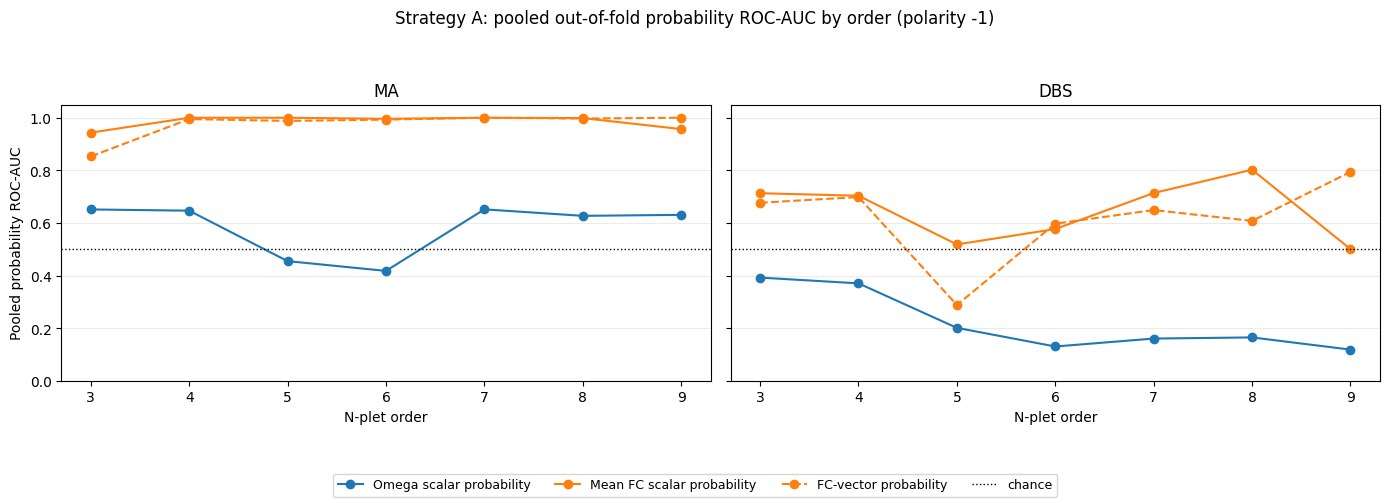

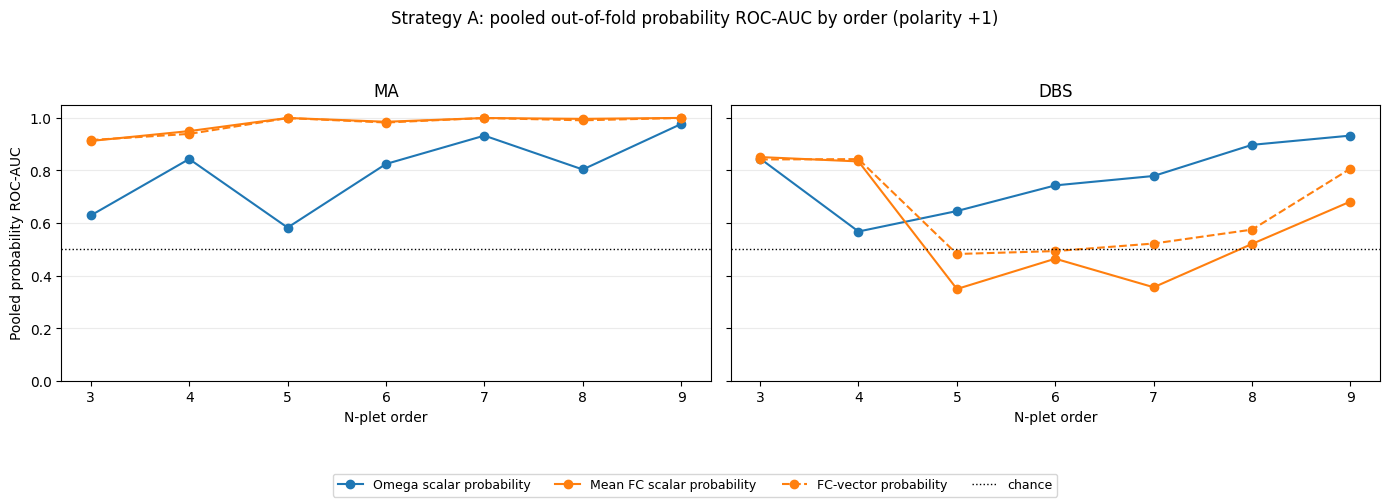

In [8]:
import matplotlib.pyplot as plt

probability_predictions = pd.concat([result.predictions for result in results.values()], ignore_index=True)
validate_oof(probability_predictions, EXHAUSTIVE_ORDERS + ANNEALING_ORDERS,
             [('omega', 'scalar'), ('fc', 'scalar'), ('fc', 'pairwise_vector')])
metrics = pd.concat([result.metrics for result in results.values()], ignore_index=True)
display(metrics)
PLOT_ORDERS = EXHAUSTIVE_ORDERS + ANNEALING_ORDERS
probability_styles = {
    ('omega', 'scalar'): ('Omega scalar probability', 'tab:blue', '-'),
    ('fc', 'scalar'): ('Mean FC scalar probability', 'tab:orange', '-'),
    ('fc', 'pairwise_vector'): ('FC-vector probability', 'tab:orange', '--'),
}
for polarity in (-1, 1):
    fig, axes = plt.subplots(
        1, len(DATASETS), squeeze=False, sharey=True,
        figsize=(7 * len(DATASETS), 5),
    )
    for dataset, ax in zip(DATASETS, axes[0]):
        for (measure, model), (label, color, linestyle) in probability_styles.items():
            group = metrics.loc[
                (metrics['dataset'] == dataset)
                & (metrics['polarity'] == polarity)
                & (metrics['selection_measure'] == measure)
                & (metrics['model'] == model)
                & metrics['order'].isin(PLOT_ORDERS)
            ].sort_values('order')
            if group['order'].duplicated().any() or set(group['order']) != set(PLOT_ORDERS):
                raise ValueError(f'Incomplete or duplicate probability-performance orders for {dataset}, {measure}, {model}, polarity {polarity}.')
            if not np.isfinite(group['roc_auc'].to_numpy(dtype=float)).all():
                raise ValueError(f'Non-finite probability-performance AUC for {dataset}, {measure}, {model}, polarity {polarity}.')
            ax.plot(
                group['order'], group['roc_auc'], marker='o', color=color,
                linestyle=linestyle, label=label,
            )
        ax.axhline(0.5, color='black', linestyle=':', linewidth=1, label='chance')
        ax.set(title=dataset, xlabel='N-plet order', xticks=PLOT_ORDERS, ylim=(0, 1.05))
        ax.grid(axis='y', alpha=0.25)
    axes[0, 0].set_ylabel('Pooled probability ROC-AUC')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=9)
    fig.suptitle(f'Strategy A: pooled out-of-fold probability ROC-AUC by order (polarity {polarity:+d})')
    fig.tight_layout(rect=(0, 0.12, 1, 0.93))
    plt.show()

### Retain out-of-fold raw Omega values
Each value below was calculated on a held-out scan using the n-plet selected without that animal. Keep the fold, n-plet and selection polarity with every value; do not aggregate away these identifiers. This table supports pooled raw-Omega evaluation only.

In [9]:
predictions = pd.concat([result.predictions for result in results.values()], ignore_index=True)
omega_oof_predictions = predictions.loc[
    (predictions['selection_measure'] == 'omega')
    & (predictions['model'] == 'scalar')
].copy()
missing_omega = omega_oof_predictions['raw_omega'].isna()
if missing_omega.any():
    context = omega_oof_predictions.loc[missing_omega,
        ['dataset', 'held_out_animal', 'order', 'selection_measure', 'polarity', 'state', 'scan_index']]
    raise ValueError(f'Missing held-out raw Omega: {context.to_dict("records")}')
validate_oof(omega_oof_predictions, EXHAUSTIVE_ORDERS + ANNEALING_ORDERS, [('omega', 'scalar')])
omega_oof_predictions['omega_score'] = (
    omega_oof_predictions['polarity'] * omega_oof_predictions['raw_omega']
)
omega_oof_predictions['score_definition'] = 'training-selected polarity x held-out raw Omega'
omega_oof_path = OUTPUT / 'omega_oof_predictions.csv'
omega_oof_predictions.to_csv(omega_oof_path, index=False)
print(f'Saved {len(omega_oof_predictions)} fold-specific Omega scores to {omega_oof_path}')
display(omega_oof_predictions[
    ['dataset', 'held_out_animal', 'state', 'scan_index', 'responsive', 'order',
     'polarity', 'nplet', 'raw_omega', 'omega_score']
].head(12))

Saved 2520 fold-specific Omega scores to c:\CAMILO\Brain_Entropy\REPO\high-order-anesthesia\results\R1_A2_loao_anova\omega_oof_predictions.csv


,dataset,held_out_animal,state,scan_index,responsive,order,polarity,nplet,raw_omega,omega_score
0,MA,A,MA_awake,0,1,3,1,"[26, 27, 63]",-0.010684,-0.010684
1,MA,A,MA_awake,1,1,3,1,"[26, 27, 63]",-0.167695,-0.167695
2,MA,A,MA_awake,0,1,3,-1,"[12, 18, 22]",0.074069,-0.074069
3,MA,A,MA_awake,1,1,3,-1,"[12, 18, 22]",0.007358,-0.007358
12,MA,A,MA_awake,0,1,4,1,"[27, 28, 59, 69]",0.723979,0.723979
13,MA,A,MA_awake,1,1,4,1,"[27, 28, 59, 69]",0.378238,0.378238
14,MA,A,MA_awake,0,1,4,-1,"[29, 38, 40, 61]",-0.242302,0.242302
15,MA,A,MA_awake,1,1,4,-1,"[29, 38, 40, 61]",-0.088504,0.088504
24,MA,A,MA_awake,0,1,5,1,"[26, 59, 63, 69, 78]",-0.269360,-0.269360
25,MA,A,MA_awake,1,1,5,1,"[26, 59, 63, 69, 78]",-0.293964,-0.293964


### Prepare pooled raw-Omega metrics
Pool held-out raw Omega across animals, separately for each dataset, order and polarity. Compute animal-balanced ROC-AUC and weighted average precision directly from the polarity-oriented scores, without probability calibration.

In [10]:
OMEGA_POOLED_KEYS = ['dataset', 'order', 'selection_measure', 'polarity']
validate_oof(omega_oof_predictions, EXHAUSTIVE_ORDERS + ANNEALING_ORDERS, [('omega', 'scalar')])
pooled_omega_rows = []
for key, group in omega_oof_predictions.groupby(OMEGA_POOLED_KEYS, sort=True):
    if group.duplicated(['state', 'scan_index']).any():
        raise ValueError(f'Duplicate held-out raw-Omega scans for {key}.')
    labels = group['responsive'].to_numpy(dtype=int)
    scores = group['omega_score'].to_numpy(dtype=float)
    if not np.isfinite(scores).all():
        raise ValueError(f'Non-finite held-out raw Omega for {key}.')
    sample_weights = animal_balanced_weights(labels, group['animal'].astype(str))
    pooled_omega_rows.append({
        **dict(zip(OMEGA_POOLED_KEYS, key)),
        'roc_auc': roc_auc_score(labels, scores, sample_weight=sample_weights),
        'pr_auc': average_precision_score(labels, scores, sample_weight=sample_weights),
        'weighted_prevalence': float(np.average(labels, weights=sample_weights)),
        'n_scans': len(group), 'n_animals': group['animal'].nunique(),
    })
pooled_omega_metrics = pd.DataFrame(pooled_omega_rows)
pooled_omega_path = OUTPUT / 'omega_pooled_metrics.csv'
pooled_omega_metrics.to_csv(pooled_omega_path, index=False)
print(f'Saved pooled raw-Omega metrics to {pooled_omega_path}')

Saved pooled raw-Omega metrics to c:\CAMILO\Brain_Entropy\REPO\high-order-anesthesia\results\R1_A2_loao_anova\omega_pooled_metrics.csv


## Strategy B: pooled held-out raw Omega and pairwise FC
Compare raw Omega on Omega-selected n-plets with raw mean pairwise FC on FC-selected n-plets, without logistic probabilities or per-animal AUC averaging. Pairwise FC is the mean Fisher-z edge value, matching the search measure. Each score is multiplied by its own measure's selection polarity. Single-class animals contribute to pooled evaluation. Display pooled ROC-AUC and weighted average precision in the table, and ROC-AUC across all orders in the lineplots. The two measures select their regions independently; this is not a matched-regions comparison.

Prepared pooled raw pairwise metrics without probability fitting.


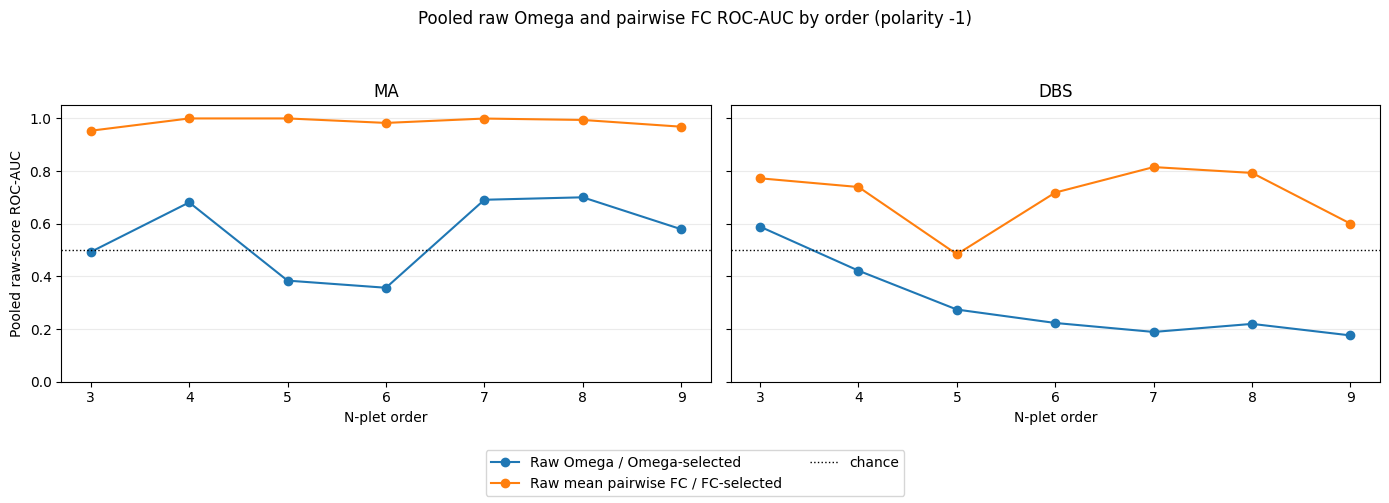

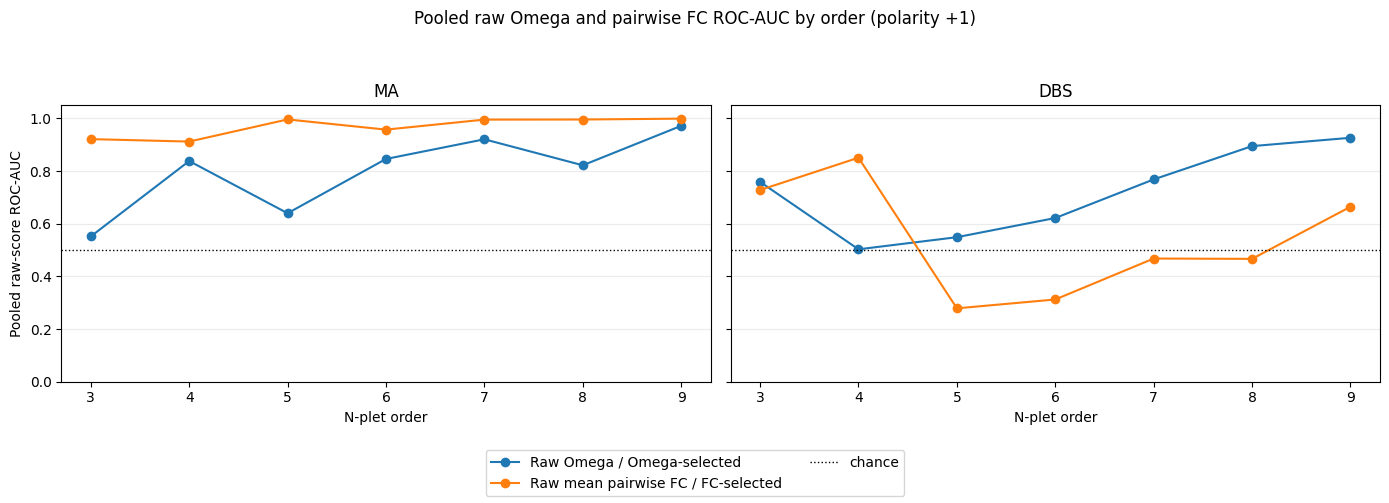

In [11]:

import matplotlib.pyplot as plt

PLOT_ORDERS = EXHAUSTIVE_ORDERS + ANNEALING_ORDERS
raw_pairwise_predictions = predictions.loc[
    (predictions["selection_measure"] == "fc")
    & (predictions["model"] == "scalar")
    & predictions["order"].isin(PLOT_ORDERS)
].copy()
raw_pairwise_predictions["raw_pairwise"] = raw_pairwise_predictions["raw_value"]
raw_pairwise_predictions["pairwise_score"] = (
    raw_pairwise_predictions["polarity"] * raw_pairwise_predictions["raw_pairwise"]
)
validate_oof(raw_pairwise_predictions, PLOT_ORDERS, [('fc', 'scalar')])
pairwise_pooled_rows = []
for key, group in raw_pairwise_predictions.groupby(OMEGA_POOLED_KEYS, sort=True):
    if group.duplicated(["state", "scan_index"]).any():
        raise ValueError(f"Duplicate held-out raw pairwise scans for {key}.")
    labels = group["responsive"].to_numpy(dtype=int)
    scores = group["pairwise_score"].to_numpy(dtype=float)
    if not np.isfinite(scores).all():
        raise ValueError(f"Non-finite held-out raw pairwise values for {key}.")
    sample_weights = animal_balanced_weights(labels, group["animal"].astype(str))
    pairwise_pooled_rows.append({
        **dict(zip(OMEGA_POOLED_KEYS, key)),
        "roc_auc": roc_auc_score(labels, scores, sample_weight=sample_weights),
        "pr_auc": average_precision_score(labels, scores, sample_weight=sample_weights),
        "weighted_prevalence": float(np.average(labels, weights=sample_weights)),
        "n_scans": len(group), "n_animals": group["animal"].nunique(),
    })
pooled_pairwise_metrics = pd.DataFrame(pairwise_pooled_rows)
raw_pairwise_predictions.to_csv(OUTPUT / "pairwise_oof_raw_values.csv", index=False)
pooled_pairwise_metrics.to_csv(OUTPUT / "pairwise_pooled_raw_metrics.csv", index=False)
print("Prepared pooled raw pairwise metrics without probability fitting.")
pairwise_plot_metrics = pooled_pairwise_metrics.copy()
pairwise_plot_metrics["predictor"] = "Raw mean pairwise FC / FC-selected"
raw_pooled_metrics = pd.concat([
    pooled_omega_metrics.assign(predictor="Raw Omega / Omega-selected"),
    pairwise_plot_metrics,
], ignore_index=True)
# display(raw_pooled_metrics)

def best_raw_omega_order(dataset, polarity):
    candidates = pooled_omega_metrics.loc[
        (pooled_omega_metrics["dataset"] == dataset)
        & (pooled_omega_metrics["selection_measure"] == "omega")
        & (pooled_omega_metrics["polarity"] == polarity)
    ].sort_values("order")
    if candidates.empty or not np.isfinite(candidates["roc_auc"].to_numpy(dtype=float)).all():
        raise ValueError(f"Invalid pooled raw-Omega metrics for {dataset}, polarity {polarity}.")
    return int(candidates.loc[candidates["roc_auc"].idxmax(), "order"])

def best_raw_fc_order(dataset, polarity):
    candidates = pooled_pairwise_metrics.loc[
        (pooled_pairwise_metrics["dataset"] == dataset)
        & (pooled_pairwise_metrics["selection_measure"] == "fc")
        & (pooled_pairwise_metrics["polarity"] == polarity)
    ].sort_values("order")
    if candidates.empty or not np.isfinite(candidates["roc_auc"].to_numpy(dtype=float)).all():
        raise ValueError(f"Invalid pooled raw-FC metrics for {dataset}, polarity {polarity}.")
    return int(candidates.loc[candidates["roc_auc"].idxmax(), "order"])

RAW_SCORE_STYLES = {
    "Raw Omega / Omega-selected": ("tab:blue", "-"),
    "Raw mean pairwise FC / FC-selected": ("tab:orange", "-"),
}
for polarity in (-1, 1):
    fig, axes = plt.subplots(
        1, len(DATASETS), squeeze=False, sharey=True,
        figsize=(7 * len(DATASETS), 5),
    )
    for dataset, ax in zip(DATASETS, axes[0]):
        for predictor, (color, linestyle) in RAW_SCORE_STYLES.items():
            group = raw_pooled_metrics.loc[
                (raw_pooled_metrics["dataset"] == dataset)
                & (raw_pooled_metrics["polarity"] == polarity)
                & (raw_pooled_metrics["predictor"] == predictor)
            ].sort_values("order")
            if group["order"].duplicated().any() or set(group["order"]) != set(PLOT_ORDERS):
                raise ValueError(f"Incomplete or duplicate pooled raw-score orders for {dataset}, {predictor}, polarity {polarity}.")
            if not np.isfinite(group["roc_auc"].to_numpy(dtype=float)).all():
                raise ValueError(f"Non-finite pooled raw-score AUC for {dataset}, {predictor}, polarity {polarity}.")
            ax.plot(
                group["order"], group["roc_auc"], marker="o", color=color,
                linestyle=linestyle, label=predictor,
            )
        ax.axhline(0.5, color="black", linestyle=":", linewidth=1, label="chance")
        ax.set(title=dataset, xlabel="N-plet order", xticks=PLOT_ORDERS, ylim=(0, 1.05))
        ax.grid(axis="y", alpha=0.25)
    axes[0, 0].set_ylabel("Pooled raw-score ROC-AUC")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2)
    fig.suptitle(f"Pooled raw Omega and pairwise FC ROC-AUC by order (polarity {polarity:+d})")
    fig.tight_layout(rect=(0, 0.12, 1, 0.93))
    plt.show()

## Additional comparison: both scalars on Omega-selected n-plets
Use only each training fold's already selected raw-Omega n-plet, separately by order and Omega-selection polarity. Reuse its saved held-out Omega values and logistic probabilities unchanged. Extract mean within-n-plet Fisher-z FC from the already-loaded covariance matrices for those exact regions, caching each subset's FC values across scans. No Omega calculation, preprocessing, subset search or vector model is performed here.

Fit only the matched mean-FC scalar logistic model, using the existing weighted training-only scaling and fixed C=1 fitting procedure. Pool held-out predictions across animals. Report animal-balanced ROC-AUC and weighted average precision for (A) logistic probabilities and (B) polarity-oriented raw Omega and mean FC. The FC raw-score direction uses the Omega-selection polarity, not an independently optimized FC direction. No best-order selection, probability distributions or within-animal AUC/AP are included. Existing cells and results are unchanged.

In [12]:
from src.hoi_anesthesia.utils import pairwise_fisher_z
from src.hoi_anesthesia.validation import fit_probabilities, loao_folds

omega_matched_orders = EXHAUSTIVE_ORDERS + ANNEALING_ORDERS
omega_matched_source = pd.concat(
    [result.predictions for result in results.values()], ignore_index=True,
)
omega_matched_source = omega_matched_source.loc[
    omega_matched_source['selection_measure'].eq('omega')
    & omega_matched_source['model'].eq('scalar')
    & omega_matched_source['order'].isin(omega_matched_orders)
].copy()
omega_matched_frames = []
omega_matched_fc_cache = {}
for dataset in DATASETS:
    matched_covariances, matched_metadata = inputs[dataset]
    matched_metadata = matched_metadata.reset_index(drop=True)
    matched_tensor = torch.as_tensor(matched_covariances, dtype=torch.float64, device=DEVICE)
    for animal, train, test in loao_folds(matched_metadata):
        matched_train_rows = matched_metadata.iloc[train]
        matched_labels = matched_train_rows['responsive'].to_numpy(dtype=int)
        matched_weights = animal_balanced_weights(
            matched_labels, matched_train_rows['animal'].astype(str).to_numpy(),
        )
        matched_expected = matched_metadata.iloc[test].set_index(['state', 'scan_index'])
        for order in omega_matched_orders:
            for polarity in (-1, 1):
                matched_context = f'{dataset}, animal {animal}, order {order}, polarity {polarity}'
                matched_fold = omega_matched_source.loc[
                    omega_matched_source['dataset'].eq(dataset)
                    & omega_matched_source['held_out_animal'].astype(str).eq(str(animal))
                    & omega_matched_source['order'].eq(order)
                    & omega_matched_source['polarity'].eq(polarity)
                ].set_index(['state', 'scan_index'])
                if (matched_fold.index.has_duplicates
                        or len(matched_fold) != len(matched_expected)
                        or set(matched_fold.index) != set(matched_expected.index)):
                    raise ValueError(f'Incomplete or duplicate Omega-held-out scan coverage: {matched_context}.')
                matched_fold = matched_fold.reindex(matched_expected.index)
                if (not matched_fold['animal'].astype(str).eq(str(animal)).all()
                        or not np.array_equal(matched_fold['responsive'], matched_expected['responsive'])):
                    raise ValueError(f'Omega-held-out scan identities/labels disagree: {matched_context}.')
                matched_nplets = {tuple(int(region) for region in nplet) for nplet in matched_fold['nplet']}
                if len(matched_nplets) != 1:
                    raise ValueError(f'Inconsistent Omega-selected n-plets: {matched_context}.')
                matched_nplet = next(iter(matched_nplets))
                if (len(matched_nplet) != order or len(set(matched_nplet)) != order
                        or min(matched_nplet) < 0 or max(matched_nplet) >= matched_covariances.shape[-1]):
                    raise ValueError(f'Invalid Omega-selected n-plet: {matched_context}.')
                matched_omega_values = matched_fold['raw_omega'].to_numpy(dtype=float)
                matched_omega_probability = matched_fold['probability'].to_numpy(dtype=float)
                if (not np.isfinite(matched_omega_values).all()
                        or not np.isfinite(matched_omega_probability).all()
                        or np.any((matched_omega_probability < 0) | (matched_omega_probability > 1))):
                    raise ValueError(f'Invalid saved Omega values/probabilities: {matched_context}.')
                matched_cache_key = (dataset, matched_nplet)
                if matched_cache_key not in omega_matched_fc_cache:
                    omega_matched_fc_cache[matched_cache_key] = pairwise_fisher_z(
                        matched_tensor,
                        torch.as_tensor([matched_nplet], dtype=torch.long, device=DEVICE),
                    )[0].mean(dim=-1).cpu().numpy()
                matched_fc_values = omega_matched_fc_cache[matched_cache_key]
                if not np.isfinite(matched_fc_values).all():
                    raise ValueError(f'Non-finite matched mean-FC values: {matched_context}.')
                matched_fc_features = polarity * matched_fc_values[:, None]
                try:
                    matched_fc_probability, _, _ = fit_probabilities(
                        matched_fc_features[train], matched_fc_features[test], matched_labels, matched_weights,
                    )
                except (ValueError, RuntimeError) as error:
                    raise RuntimeError(f'Matched mean-FC scalar fit failed: {matched_context}: {error}') from error
                for predictor, raw_values, probability in (
                    ('Omega scalar', matched_omega_values, matched_omega_probability),
                    ('Mean FC scalar', matched_fc_values[test], matched_fc_probability),
                ):
                    matched_frame = matched_expected.reset_index().copy()
                    matched_frame['held_out_animal'] = str(animal)
                    matched_frame['order'] = order
                    matched_frame['polarity'] = polarity
                    matched_frame['nplet'] = [matched_nplet] * len(test)
                    matched_frame['selection_measure'] = 'omega'
                    matched_frame['predictor'] = predictor
                    matched_frame['raw_value'] = raw_values
                    matched_frame['raw_score'] = polarity * raw_values
                    matched_frame['probability'] = probability
                    omega_matched_frames.append(matched_frame)
omega_matched_predictions = pd.concat(omega_matched_frames, ignore_index=True)
validate_oof(omega_matched_predictions, omega_matched_orders,
             [('omega', 'Omega scalar'), ('omega', 'Mean FC scalar')], model_column='predictor')
omega_matched_metric_rows = []
omega_matched_keys = ['dataset', 'order', 'polarity', 'predictor']
for key, group in omega_matched_predictions.groupby(omega_matched_keys, sort=True):
    if group.duplicated(['state', 'scan_index']).any():
        raise ValueError(f'Duplicate pooled matched-input scans for {key}.')
    matched_y = group['responsive'].to_numpy(dtype=int)
    matched_w = animal_balanced_weights(matched_y, group['animal'].astype(str).to_numpy())
    for evaluation, column in (('probability', 'probability'), ('raw', 'raw_score')):
        matched_scores = group[column].to_numpy(dtype=float)
        if not np.isfinite(matched_scores).all():
            raise ValueError(f'Non-finite matched-input {evaluation} scores for {key}.')
        omega_matched_metric_rows.append({
            **dict(zip(omega_matched_keys, key)), 'evaluation': evaluation,
            'roc_auc': roc_auc_score(matched_y, matched_scores, sample_weight=matched_w),
            'average_precision': average_precision_score(matched_y, matched_scores, sample_weight=matched_w),
            'weighted_prevalence': float(np.average(matched_y, weights=matched_w)),
            'n_scans': len(group), 'n_animals': group['animal'].nunique(),
        })
omega_matched_metrics = pd.DataFrame(omega_matched_metric_rows)

def plot_omega_matched_scalars(evaluation):
    import matplotlib.pyplot as plt

    for polarity in (-1, 1):
        fig, axes = plt.subplots(
            1, len(DATASETS), squeeze=False, sharey=True,
            figsize=(7 * len(DATASETS), 5),
        )
        for dataset_index, dataset in enumerate(DATASETS):
            for row, (metric, ylabel) in enumerate((
                ('roc_auc', 'Pooled ROC-AUC'),
            )):
                ax = axes[row, dataset_index]
                for predictor, color in (('Omega scalar', 'tab:blue'), ('Mean FC scalar', 'tab:orange')):
                    group = omega_matched_metrics.loc[
                        omega_matched_metrics['dataset'].eq(dataset)
                        & omega_matched_metrics['polarity'].eq(polarity)
                        & omega_matched_metrics['evaluation'].eq(evaluation)
                        & omega_matched_metrics['predictor'].eq(predictor)
                    ].sort_values('order')
                    if group['order'].duplicated().any() or set(group['order']) != set(omega_matched_orders):
                        raise ValueError(f'Incomplete matched-input metrics: {dataset}, {predictor}, {evaluation}, {polarity}.')
                    ax.plot(group['order'], group[metric], marker='o', color=color, label=predictor)
                ax.axhline(0.5, color='black', linestyle=':', linewidth=1, label='chance / balanced prevalence')
                ax.set(title=dataset, xlabel='N-plet order', xticks=omega_matched_orders, ylim=(0, 1.05))
                ax.grid(axis='y', alpha=0.25)
                if dataset_index == 0:
                    ax.set_ylabel(ylabel)
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.legend(handles, labels, loc='lower center', ncol=3)
        fig.suptitle(f'Omega-selected n-plets: {evaluation} performance (Omega polarity {polarity:+d})')
        fig.tight_layout(rect=(0, 0.06, 1, 0.94))
        plt.show()

### A. Model-probability performance on the same Omega-selected regions
Compare reused Omega-scalar probabilities against training-only matched mean-FC scalar logistic probabilities. Plot pooled held-out ROC-AUC and weighted average precision for every order and both Omega-selection polarities.

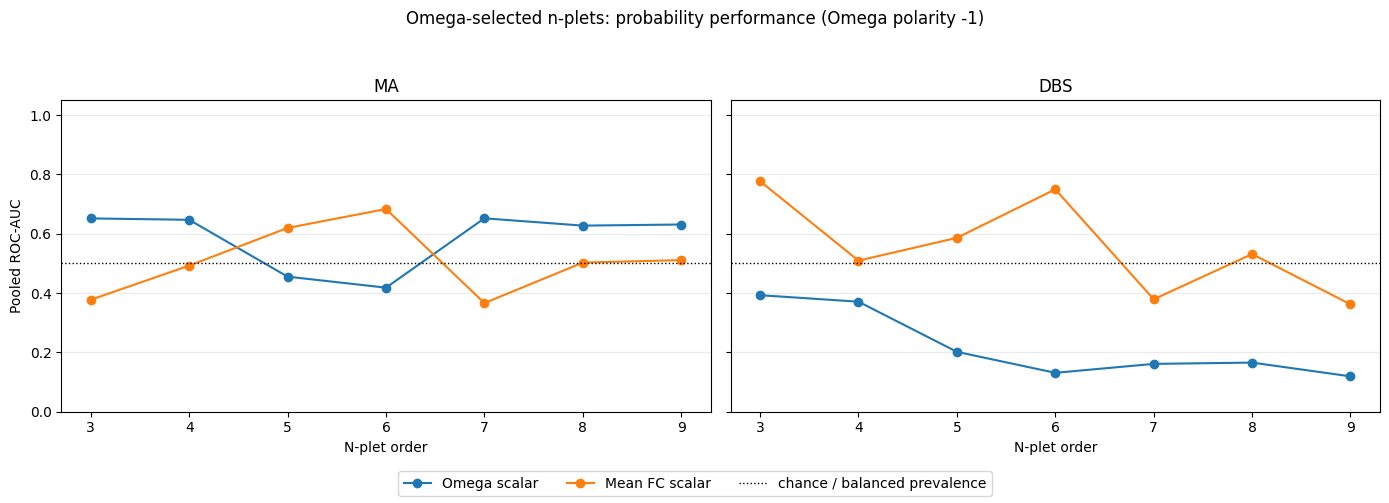

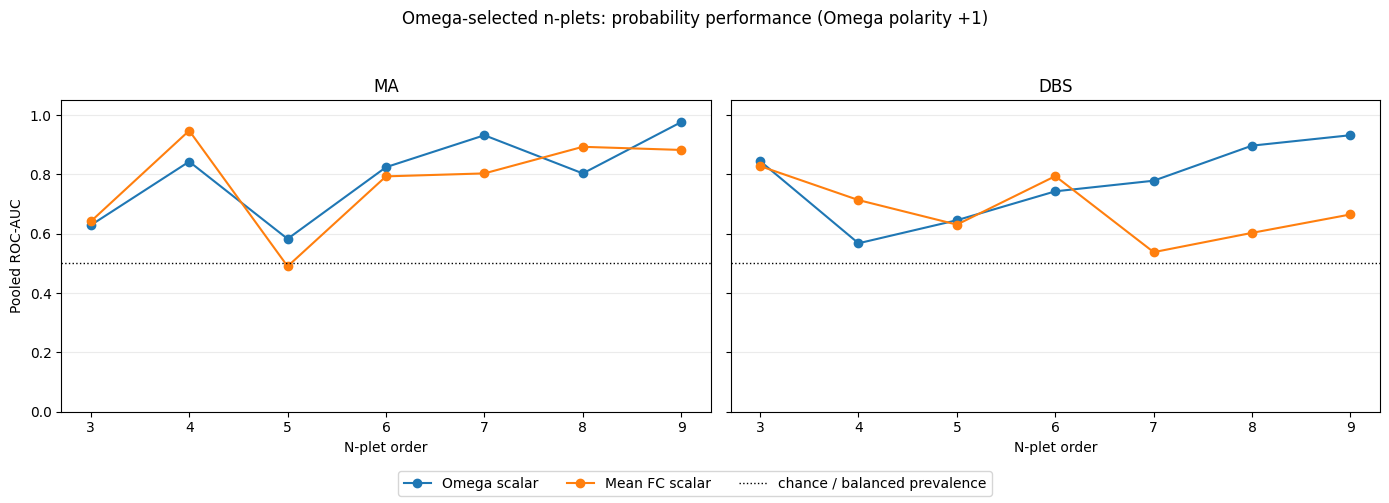

In [13]:
# display(omega_matched_metrics.loc[omega_matched_metrics['evaluation'].eq('probability')])
plot_omega_matched_scalars('probability')

### B. Raw-measure performance on the same Omega-selected regions
Compare reused raw Omega against the same extracted mean Fisher-z FC values used above, multiplying both raw scalars by the Omega-selection polarity. Plot pooled held-out ROC-AUC and weighted average precision for every order. No probabilities or within-animal metrics enter this evaluation.

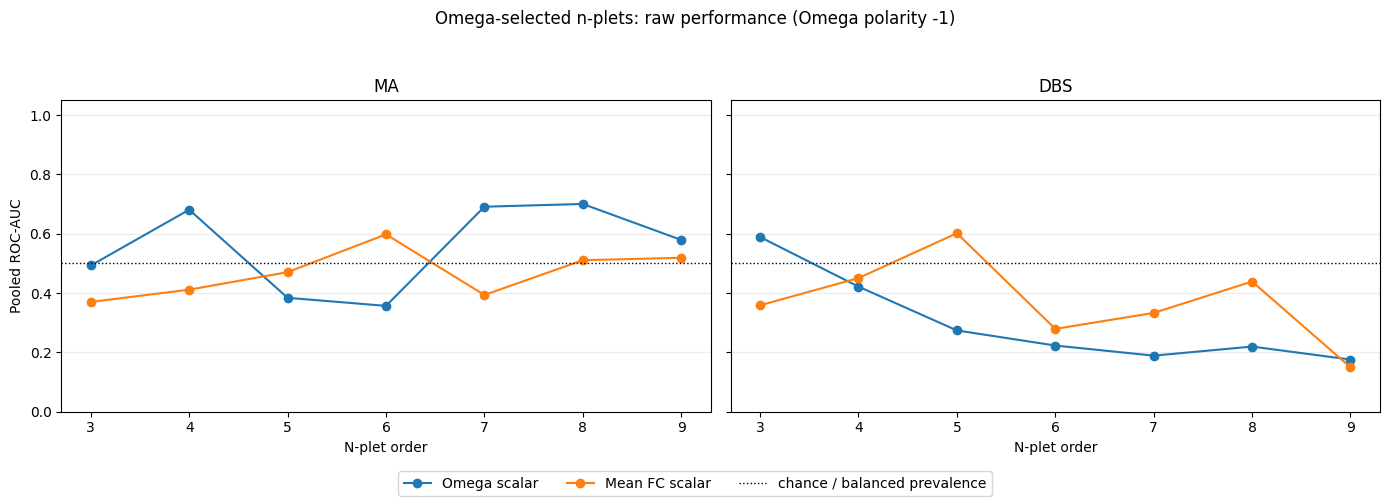

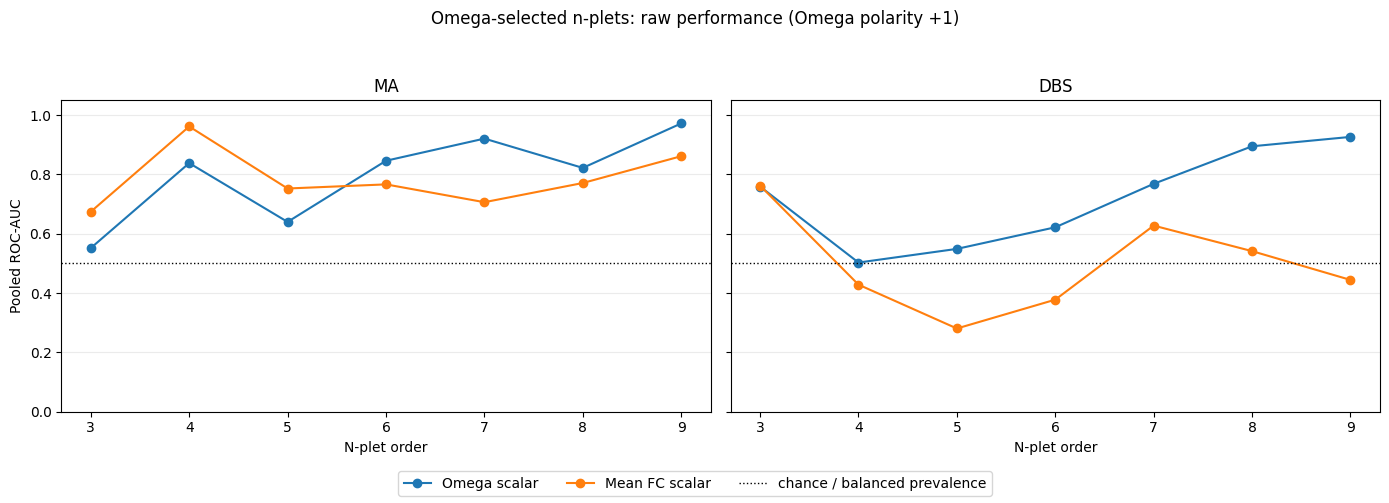

In [14]:
# display(omega_matched_metrics.loc[omega_matched_metrics['evaluation'].eq('raw')])
plot_omega_matched_scalars('raw')